In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import os

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices('GPU'))

TensorFlow version: 2.21.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [9]:
# Check GPU details

gpu = tf.config.list_physical_devices('GPU')

if gpu:
    print("GPU detected successfully!")
    print("GPU:", gpu[0])
else:
    print("No GPU detected.")

GPU detected successfully!
GPU: PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')


In [1]:
import os
from google.colab import userdata

os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")

print("Kaggle token loaded successfully!")

Kaggle token loaded successfully!


In [2]:
!pip install -q kaggle

import os

os.environ["KAGGLE_API_TOKEN"] = os.environ["KAGGLE_API_TOKEN"]

!kaggle datasets download -d dansbecker/food-101 -p /content/food101

Dataset URL: https://www.kaggle.com/datasets/dansbecker/food-101
License(s): other
100% 9.38G/9.38G [01:34<00:00, 106MB/s] 



In [3]:
import zipfile
import os

zip_path = "/content/food101/food-101.zip"
extract_path = "/content/food101_data"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Extraction completed!")
print(os.listdir(extract_path))

Extraction completed!
['food-101', 'food-101.zip']


In [4]:
import os

base_path = "/content/food101_data"

for root, dirs, files in os.walk(base_path):
    print("Folder:", root)
    print("Subfolders:", dirs[:5])
    print("Files:", files[:5])

    if root.count(os.sep) >= base_path.count(os.sep) + 2:
        break

Folder: /content/food101_data
Subfolders: ['food-101']
Files: ['food-101.zip']
Folder: /content/food101_data/food-101
Subfolders: ['food-101', '__MACOSX']
Files: []
Folder: /content/food101_data/food-101/food-101
Subfolders: ['images', 'meta']
Files: ['README.txt', 'license_agreement.txt', '.DS_Store']


In [6]:
import os

image_path = "/content/food101_data/food-101/food-101/images"

classes = sorted([
    cls for cls in os.listdir(image_path)
    if os.path.isdir(os.path.join(image_path, cls))
])

print("Total food classes:", len(classes))
print("\nFirst 10 classes:")

for cls in classes[:10]:
    cls_path = os.path.join(image_path, cls)
    count = len(os.listdir(cls_path))
    print(cls, ":", count, "images")

Total food classes: 101

First 10 classes:
apple_pie : 1000 images
baby_back_ribs : 1000 images
baklava : 1000 images
beef_carpaccio : 1000 images
beef_tartare : 1000 images
beet_salad : 1000 images
beignets : 1000 images
bibimbap : 1000 images
bread_pudding : 1000 images
breakfast_burrito : 1000 images


In [7]:
selected_classes = [
    "apple_pie",
    "baklava",
    "beignets",
    "bibimbap",
    "bread_pudding",
    "breakfast_burrito",
    "caesar_salad",
    "cheesecake",
    "chocolate_cake",
    "pizza"
]

print("Selected classes:")
for i, cls in enumerate(selected_classes, 1):
    print(i, cls)

Selected classes:
1 apple_pie
2 baklava
3 beignets
4 bibimbap
5 bread_pudding
6 breakfast_burrito
7 caesar_salad
8 cheesecake
9 chocolate_cake
10 pizza


In [8]:
import os
import numpy as np
from PIL import Image

image_path = "/content/food101_data/food-101/food-101/images"

IMG_SIZE = 64
MAX_IMAGES_PER_CLASS = 500

images = []

for cls in selected_classes:
    cls_path = os.path.join(image_path, cls)

    count = 0

    for file in os.listdir(cls_path):
        if count >= MAX_IMAGES_PER_CLASS:
            break

        file_path = os.path.join(cls_path, file)

        try:
            img = Image.open(file_path).convert("RGB")
            img = img.resize((IMG_SIZE, IMG_SIZE))
            images.append(np.array(img))
            count += 1
        except:
            pass

images = np.array(images, dtype=np.float32)

print("Dataset shape:", images.shape)
print("Total images:", len(images))
print("Image size:", images.shape[1:])

Dataset shape: (5000, 64, 64, 3)
Total images: 5000
Image size: (64, 64, 3)


In [9]:
images = (images / 127.5) - 1.0

print("Minimum pixel value:", images.min())
print("Maximum pixel value:", images.max())
print("Dataset shape:", images.shape)

Minimum pixel value: -1.0
Maximum pixel value: 1.0
Dataset shape: (5000, 64, 64, 3)


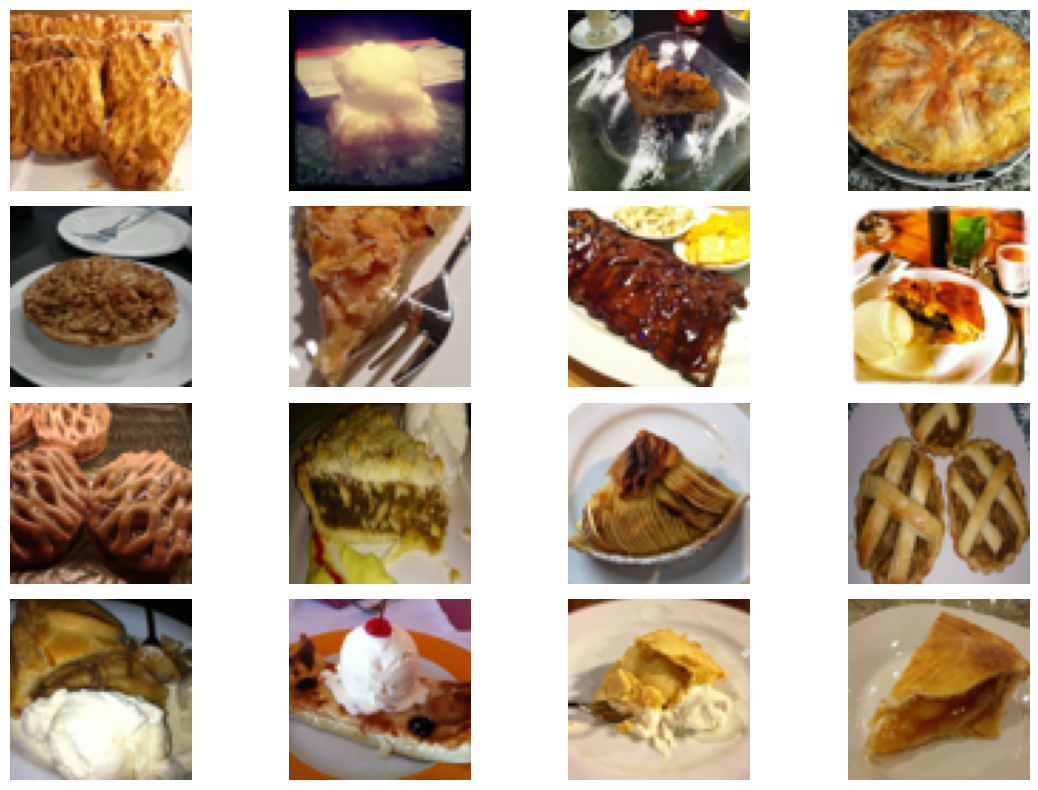

In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 8))

for i in range(16):
    plt.subplot(4, 4, i + 1)

    # Convert back from [-1, 1] to [0, 1] for display
    img = (images[i] + 1) / 2

    plt.imshow(img)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [11]:
import tensorflow as tf

BATCH_SIZE = 64

train_dataset = tf.data.Dataset.from_tensor_slices(images)

train_dataset = (
    train_dataset
    .shuffle(buffer_size=len(images))
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

print("Batch size:", BATCH_SIZE)
print("Number of batches:", len(train_dataset))

Batch size: 64
Number of batches: 79


In [12]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Reshape

LATENT_DIM = 100

generator = Sequential([
    Dense(256, activation="relu", input_shape=(LATENT_DIM,)),
    Dense(512, activation="relu"),
    Dense(1024, activation="relu"),
    Dense(64 * 64 * 3, activation="tanh"),
    Reshape((64, 64, 3))
], name="Vanilla_GAN_Generator")

generator.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "Vanilla_GAN_Generator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 256)            │        25,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 512)            │       131,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1024)           │       525,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 12288)          │    12,595,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 64, 64, 3)      │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13,277,952 (50.65 MB)

 Trainable params: 13,277,952 (50.65 MB)

 Non-trainable params: 0 (0.00 B)

In [13]:
from tensorflow.keras.layers import Flatten, Dropout

discriminator = Sequential([
    Flatten(input_shape=(64, 64, 3)),
    Dense(1024, activation="leaky_relu"),
    Dropout(0.3),
    Dense(512, activation="leaky_relu"),
    Dropout(0.3),
    Dense(256, activation="leaky_relu"),
    Dense(1, activation="sigmoid")
], name="Vanilla_GAN_Discriminator")

discriminator.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "Vanilla_GAN_Discriminator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 12288)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1024)           │    12,583,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 512)            │       524,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13,240,321 (50.51 MB)

 Trainable params: 13,240,321 (50.51 MB)

 Non-trainable params: 0 (0.00 B)

In [14]:
from tensorflow.keras.optimizers import Adam

# Compile Discriminator
discriminator.compile(
    optimizer=Adam(learning_rate=0.0002, beta_1=0.5),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Connect Generator + Discriminator
discriminator.trainable = False

gan = Sequential([
    generator,
    discriminator
], name="Vanilla_GAN")

gan.compile(
    optimizer=Adam(learning_rate=0.0002, beta_1=0.5),
    loss="binary_crossentropy"
)

print("Vanilla GAN compiled successfully!")
print("Generator:", generator.name)
print("Discriminator:", discriminator.name)

Vanilla GAN compiled successfully!
Generator: Vanilla_GAN_Generator
Discriminator: Vanilla_GAN_Discriminator


In [15]:
import numpy as np
import tensorflow as tf

def train_vanilla_gan(epochs=50):

    d_losses = []
    g_losses = []

    for epoch in range(epochs):

        epoch_d_loss = []
        epoch_g_loss = []

        for real_images in train_dataset:

            batch_size = tf.shape(real_images)[0]

            # -------------------------
            # 1. Train Discriminator
            # -------------------------

            noise = tf.random.normal([batch_size, LATENT_DIM])
            fake_images = generator(noise, training=True)

            real_labels = tf.ones((batch_size, 1))
            fake_labels = tf.zeros((batch_size, 1))

            discriminator.trainable = True

            d_loss_real = discriminator.train_on_batch(
                real_images, real_labels
            )

            d_loss_fake = discriminator.train_on_batch(
                fake_images, fake_labels
            )

            d_loss = (d_loss_real[0] + d_loss_fake[0]) / 2

            # -------------------------
            # 2. Train Generator
            # -------------------------

            discriminator.trainable = False

            noise = tf.random.normal([batch_size, LATENT_DIM])

            g_loss = gan.train_on_batch(
                noise,
                real_labels
            )

            epoch_d_loss.append(d_loss)
            epoch_g_loss.append(g_loss)

        avg_d_loss = np.mean(epoch_d_loss)
        avg_g_loss = np.mean(epoch_g_loss)

        d_losses.append(avg_d_loss)
        g_losses.append(avg_g_loss)

        print(
            f"Epoch {epoch + 1}/{epochs} "
            f"- D Loss: {avg_d_loss:.4f} "
            f"- G Loss: {avg_g_loss:.4f}"
        )

    return d_losses, g_losses

In [16]:
vanilla_d_losses, vanilla_g_losses = train_vanilla_gan(epochs=5)

Epoch 1/5 - D Loss: 0.3380 - G Loss: 0.9802
Epoch 2/5 - D Loss: 0.2561 - G Loss: 1.5727
Epoch 3/5 - D Loss: 0.2506 - G Loss: 2.1060
Epoch 4/5 - D Loss: 0.2346 - G Loss: 2.3915
Epoch 5/5 - D Loss: 0.2180 - G Loss: 2.5968


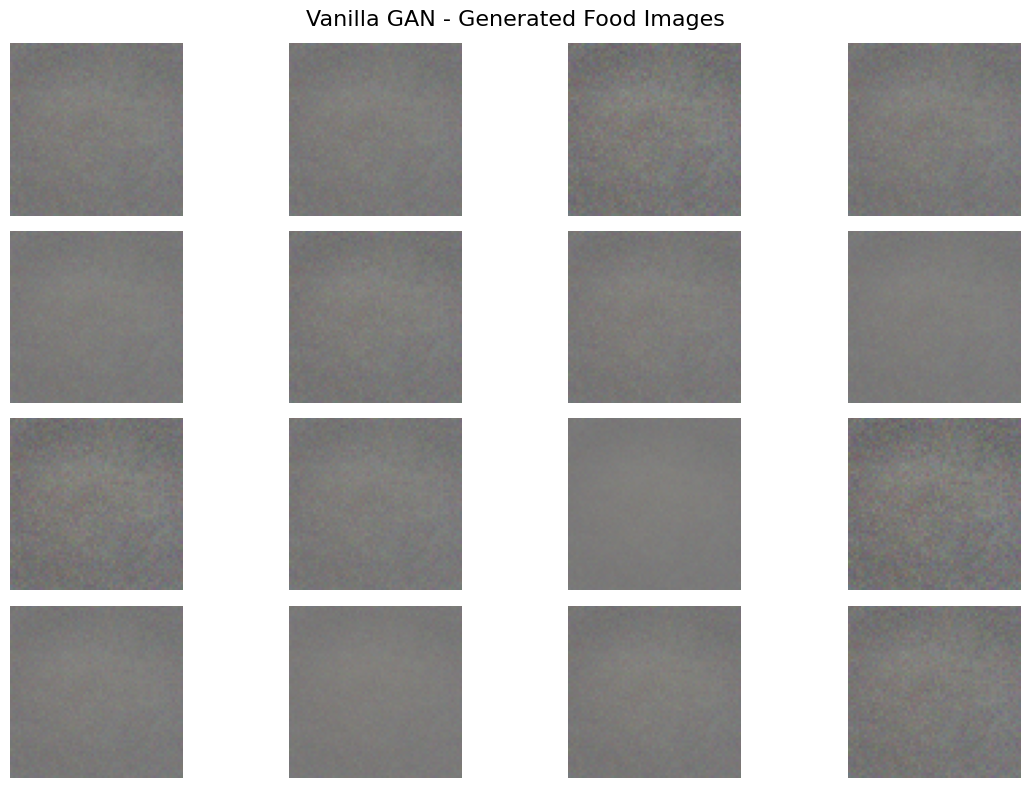

In [17]:
noise = tf.random.normal([16, LATENT_DIM])

generated_images = generator(noise, training=False)

plt.figure(figsize=(12, 8))

for i in range(16):
    plt.subplot(4, 4, i + 1)

    # Convert [-1, 1] back to [0, 1]
    img = (generated_images[i] + 1) / 2

    plt.imshow(img)
    plt.axis("off")

plt.suptitle("Vanilla GAN - Generated Food Images", fontsize=16)
plt.tight_layout()
plt.show()

In [18]:
print("Generated images shape:", generated_images.shape)
print("Minimum value:", tf.reduce_min(generated_images).numpy())
print("Maximum value:", tf.reduce_max(generated_images).numpy())
print("Mean value:", tf.reduce_mean(generated_images).numpy())
print("Standard deviation:", tf.math.reduce_std(generated_images).numpy())

Generated images shape: (16, 64, 64, 3)
Minimum value: -0.31328362
Maximum value: 0.15700312
Mean value: -0.049494434
Standard deviation: 0.04775068


In [19]:
# Make sure discriminator is trainable for its own updates
discriminator.trainable = True

d_optimizer = Adam(learning_rate=0.0002, beta_1=0.5)
g_optimizer = Adam(learning_rate=0.0002, beta_1=0.5)

bce = tf.keras.losses.BinaryCrossentropy()


@tf.function
def train_step(real_images):

    batch_size = tf.shape(real_images)[0]

    # -------------------------
    # Train Discriminator
    # -------------------------

    noise = tf.random.normal([batch_size, LATENT_DIM])

    with tf.GradientTape() as d_tape:
        fake_images = generator(noise, training=True)

        real_output = discriminator(real_images, training=True)
        fake_output = discriminator(fake_images, training=True)

        d_loss_real = bce(tf.ones_like(real_output), real_output)
        d_loss_fake = bce(tf.zeros_like(fake_output), fake_output)

        d_loss = (d_loss_real + d_loss_fake) / 2

    d_gradients = d_tape.gradient(
        d_loss, discriminator.trainable_variables
    )

    d_optimizer.apply_gradients(
        zip(d_gradients, discriminator.trainable_variables)
    )

    # -------------------------
    # Train Generator
    # -------------------------

    noise = tf.random.normal([batch_size, LATENT_DIM])

    with tf.GradientTape() as g_tape:
        fake_images = generator(noise, training=True)
        fake_output = discriminator(fake_images, training=False)

        g_loss = bce(tf.ones_like(fake_output), fake_output)

    g_gradients = g_tape.gradient(
        g_loss, generator.trainable_variables
    )

    g_optimizer.apply_gradients(
        zip(g_gradients, generator.trainable_variables)
    )

    return d_loss, g_loss


print("Improved Vanilla GAN training step created successfully!")

Improved Vanilla GAN training step created successfully!


In [20]:
vanilla_d_losses = []
vanilla_g_losses = []

EPOCHS = 5

for epoch in range(EPOCHS):

    epoch_d_loss = []
    epoch_g_loss = []

    for real_images in train_dataset:
        d_loss, g_loss = train_step(real_images)

        epoch_d_loss.append(d_loss.numpy())
        epoch_g_loss.append(g_loss.numpy())

    avg_d_loss = np.mean(epoch_d_loss)
    avg_g_loss = np.mean(epoch_g_loss)

    vanilla_d_losses.append(avg_d_loss)
    vanilla_g_losses.append(avg_g_loss)

    print(
        f"Epoch {epoch + 1}/{EPOCHS} "
        f"- D Loss: {avg_d_loss:.4f} "
        f"- G Loss: {avg_g_loss:.4f}"
    )

Epoch 1/5 - D Loss: 0.1050 - G Loss: 4.6455
Epoch 2/5 - D Loss: 0.1432 - G Loss: 4.1546
Epoch 3/5 - D Loss: 0.1769 - G Loss: 3.8129
Epoch 4/5 - D Loss: 0.1431 - G Loss: 3.7253
Epoch 5/5 - D Loss: 0.1375 - G Loss: 3.9117


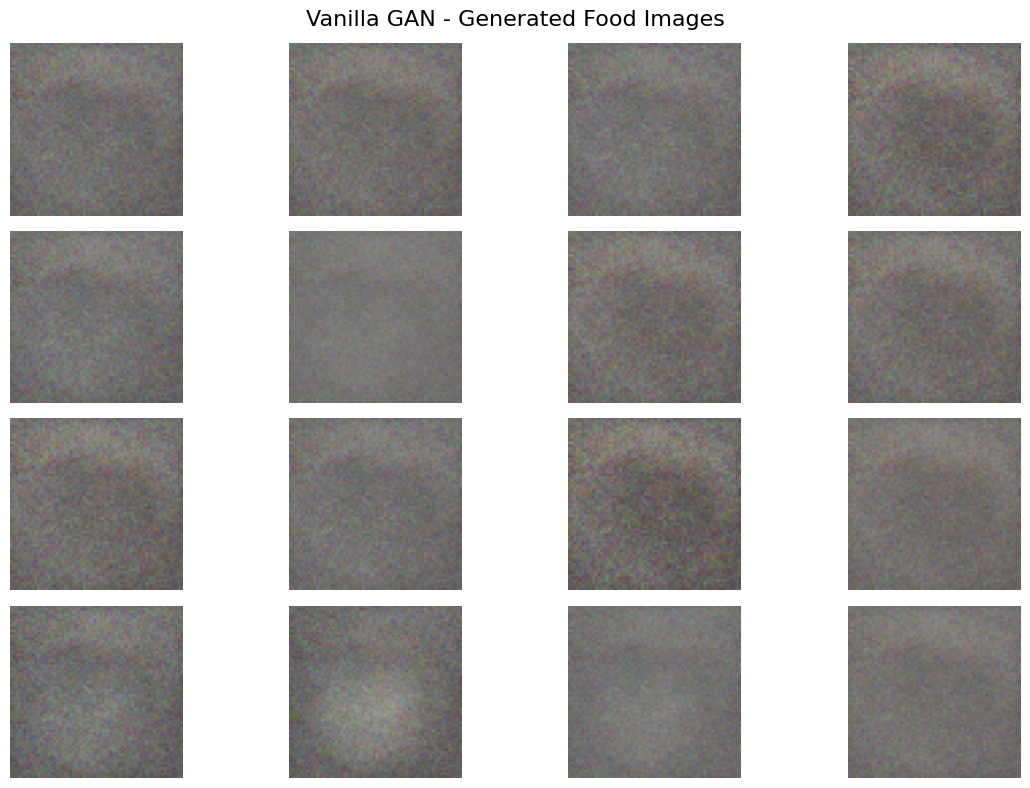

In [21]:
noise = tf.random.normal([16, LATENT_DIM])

generated_images = generator(noise, training=False)

plt.figure(figsize=(12, 8))

for i in range(16):
    plt.subplot(4, 4, i + 1)

    img = (generated_images[i] + 1) / 2
    img = tf.clip_by_value(img, 0, 1)

    plt.imshow(img)
    plt.axis("off")

plt.suptitle("Vanilla GAN - Generated Food Images", fontsize=16)
plt.tight_layout()
plt.show()

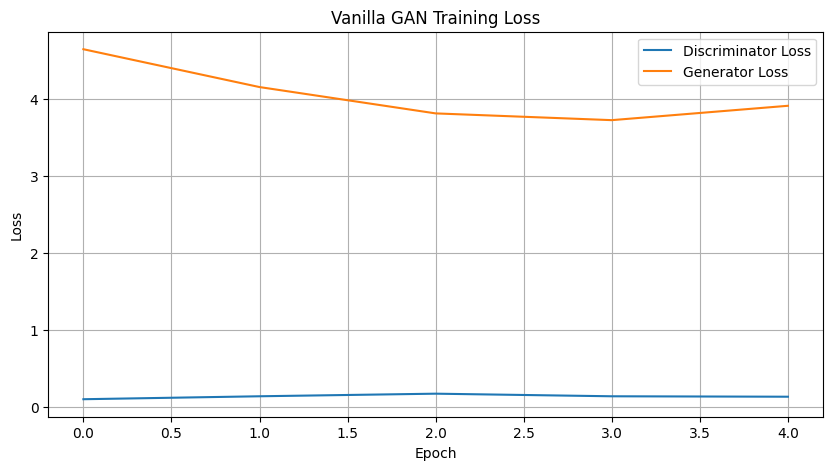

In [22]:
plt.figure(figsize=(10, 5))

plt.plot(vanilla_d_losses, label="Discriminator Loss")
plt.plot(vanilla_g_losses, label="Generator Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Vanilla GAN Training Loss")
plt.legend()
plt.grid(True)

plt.show()

In [24]:
import tensorflow as tf

BATCH_SIZE = 64

dataset = (
    tf.data.Dataset.from_tensor_slices(images)
    .shuffle(len(images))
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

print("Dataset created successfully!")
print("Number of batches:", len(dataset))

Dataset created successfully!
Number of batches: 79


In [25]:
VANILLA_EPOCHS = 20

vanilla_d_losses = []
vanilla_g_losses = []

for epoch in range(VANILLA_EPOCHS):

    epoch_d_loss = []
    epoch_g_loss = []

    for real_images in dataset:
        d_loss, g_loss = train_step(real_images)

        epoch_d_loss.append(float(d_loss))
        epoch_g_loss.append(float(g_loss))

    avg_d_loss = sum(epoch_d_loss) / len(epoch_d_loss)
    avg_g_loss = sum(epoch_g_loss) / len(epoch_g_loss)

    vanilla_d_losses.append(avg_d_loss)
    vanilla_g_losses.append(avg_g_loss)

    print(
        f"Epoch {epoch + 1}/{VANILLA_EPOCHS} "
        f"- D Loss: {avg_d_loss:.4f} "
        f"- G Loss: {avg_g_loss:.4f}"
    )

Epoch 1/20 - D Loss: 0.1473 - G Loss: 3.7185
Epoch 2/20 - D Loss: 0.1465 - G Loss: 3.6870
Epoch 3/20 - D Loss: 0.1711 - G Loss: 3.4971
Epoch 4/20 - D Loss: 0.1507 - G Loss: 3.6029
Epoch 5/20 - D Loss: 0.1524 - G Loss: 3.4497
Epoch 6/20 - D Loss: 0.1592 - G Loss: 3.4518
Epoch 7/20 - D Loss: 0.1578 - G Loss: 3.3138
Epoch 8/20 - D Loss: 0.1765 - G Loss: 3.3494
Epoch 9/20 - D Loss: 0.1622 - G Loss: 3.2222
Epoch 10/20 - D Loss: 0.1848 - G Loss: 3.0841
Epoch 11/20 - D Loss: 0.1853 - G Loss: 3.2200
Epoch 12/20 - D Loss: 0.1777 - G Loss: 3.3352
Epoch 13/20 - D Loss: 0.1922 - G Loss: 3.2794
Epoch 14/20 - D Loss: 0.1670 - G Loss: 3.2160
Epoch 15/20 - D Loss: 0.2092 - G Loss: 2.9720
Epoch 16/20 - D Loss: 0.2161 - G Loss: 2.9532
Epoch 17/20 - D Loss: 0.2512 - G Loss: 2.9334
Epoch 18/20 - D Loss: 0.2059 - G Loss: 3.0379
Epoch 19/20 - D Loss: 0.2171 - G Loss: 2.9689
Epoch 20/20 - D Loss: 0.2176 - G Loss: 2.9598


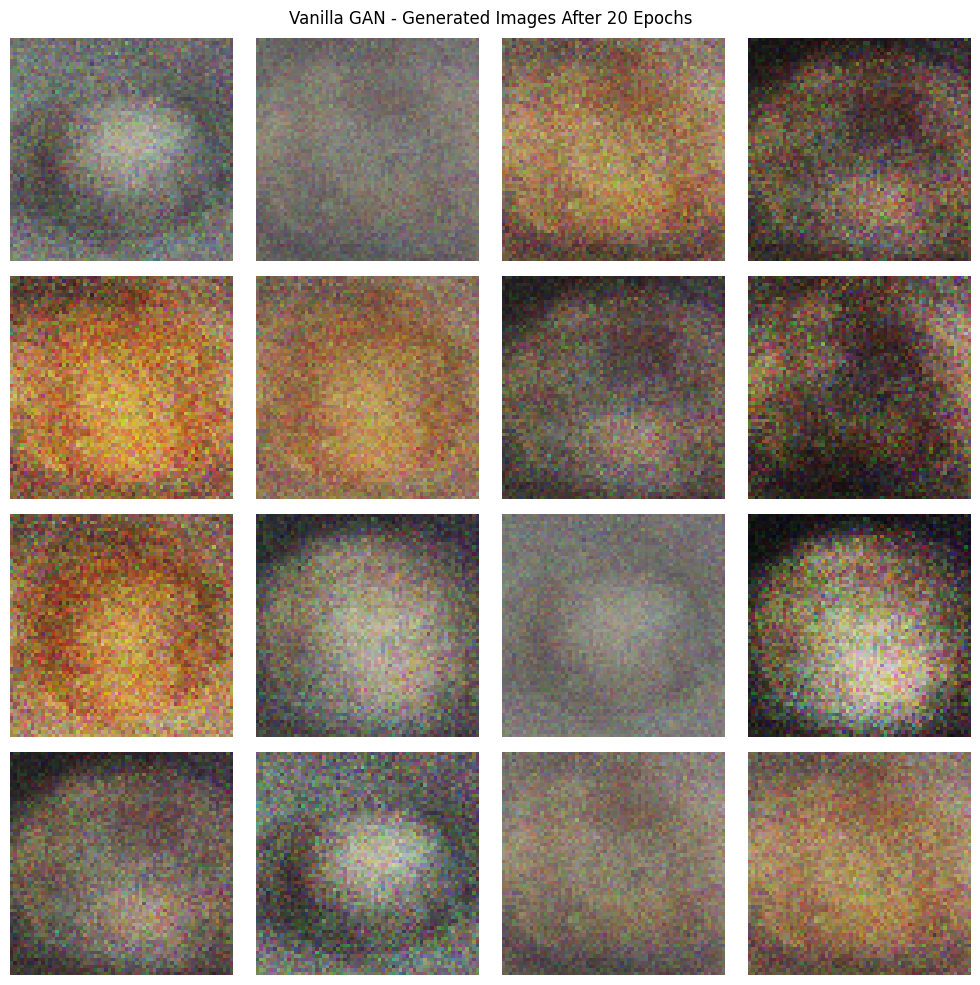

In [26]:
import matplotlib.pyplot as plt
import numpy as np

noise = tf.random.normal([16, LATENT_DIM])
generated_images = generator(noise, training=False)

# Convert [-1, 1] → [0, 1]
generated_images = (generated_images + 1) / 2.0

plt.figure(figsize=(10, 10))

for i in range(16):
    plt.subplot(4, 4, i + 1)
    plt.imshow(generated_images[i])
    plt.axis("off")

plt.suptitle("Vanilla GAN - Generated Images After 20 Epochs")
plt.tight_layout()
plt.show()

In [27]:
for epoch in range(20, 50):

    epoch_d_loss = []
    epoch_g_loss = []

    for real_images in dataset:
        d_loss, g_loss = train_step(real_images)

        epoch_d_loss.append(float(d_loss))
        epoch_g_loss.append(float(g_loss))

    avg_d_loss = sum(epoch_d_loss) / len(epoch_d_loss)
    avg_g_loss = sum(epoch_g_loss) / len(epoch_g_loss)

    vanilla_d_losses.append(avg_d_loss)
    vanilla_g_losses.append(avg_g_loss)

    print(
        f"Epoch {epoch + 1}/50 "
        f"- D Loss: {avg_d_loss:.4f} "
        f"- G Loss: {avg_g_loss:.4f}"
    )

Epoch 21/50 - D Loss: 0.2299 - G Loss: 3.0195
Epoch 22/50 - D Loss: 0.2633 - G Loss: 2.7822
Epoch 23/50 - D Loss: 0.2566 - G Loss: 2.8018
Epoch 24/50 - D Loss: 0.2185 - G Loss: 2.8171
Epoch 25/50 - D Loss: 0.2212 - G Loss: 2.9006
Epoch 26/50 - D Loss: 0.2408 - G Loss: 2.7861
Epoch 27/50 - D Loss: 0.2428 - G Loss: 2.8956
Epoch 28/50 - D Loss: 0.2022 - G Loss: 2.7902
Epoch 29/50 - D Loss: 0.2343 - G Loss: 2.7282
Epoch 30/50 - D Loss: 0.2323 - G Loss: 2.7207
Epoch 31/50 - D Loss: 0.2463 - G Loss: 2.6038
Epoch 32/50 - D Loss: 0.2268 - G Loss: 2.7470
Epoch 33/50 - D Loss: 0.2455 - G Loss: 2.8213
Epoch 34/50 - D Loss: 0.2375 - G Loss: 2.9839
Epoch 35/50 - D Loss: 0.2776 - G Loss: 2.8566
Epoch 36/50 - D Loss: 0.2791 - G Loss: 2.8339
Epoch 37/50 - D Loss: 0.2981 - G Loss: 2.6946
Epoch 38/50 - D Loss: 0.2867 - G Loss: 2.8678
Epoch 39/50 - D Loss: 0.2940 - G Loss: 2.7815
Epoch 40/50 - D Loss: 0.2679 - G Loss: 2.6505
Epoch 41/50 - D Loss: 0.3067 - G Loss: 2.6782
Epoch 42/50 - D Loss: 0.2460 - G L

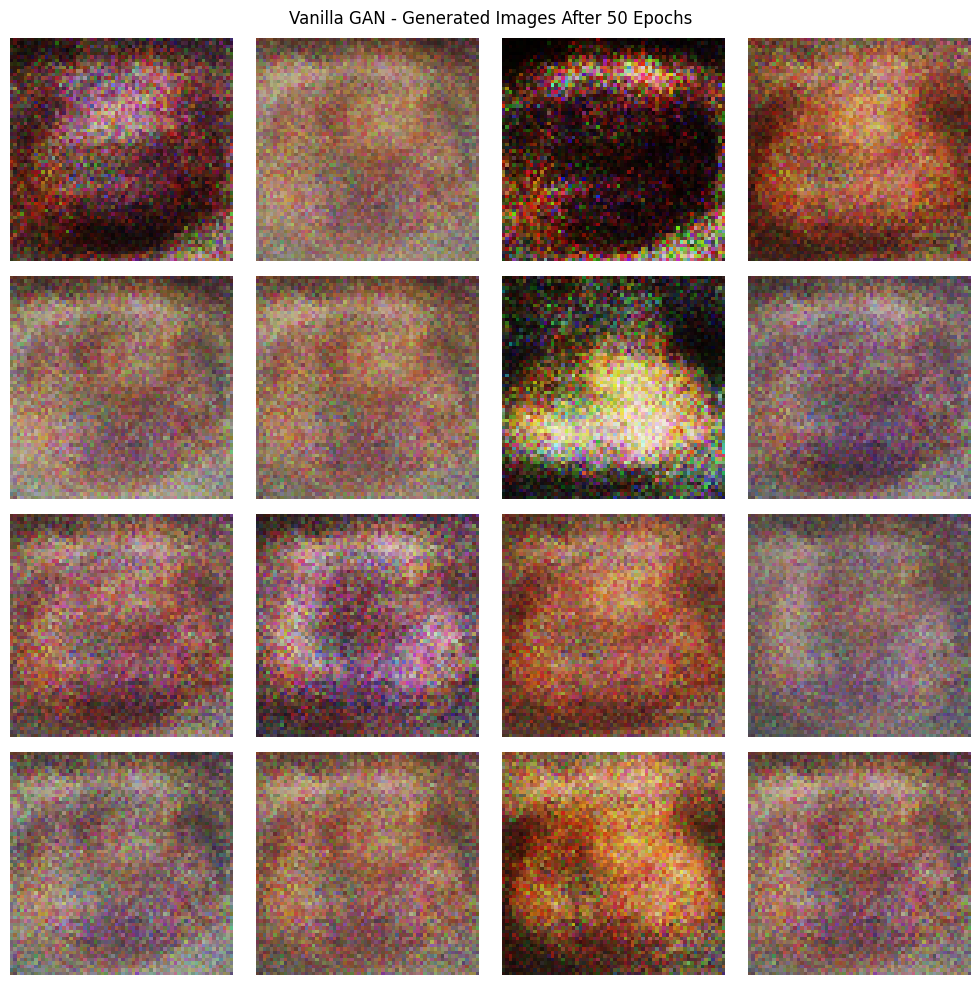

In [28]:
noise = tf.random.normal([16, LATENT_DIM])

vanilla_generated_images = generator(noise, training=False)

# Convert [-1, 1] → [0, 1]
vanilla_generated_images = (vanilla_generated_images + 1) / 2.0

plt.figure(figsize=(10, 10))

for i in range(16):
    plt.subplot(4, 4, i + 1)
    plt.imshow(vanilla_generated_images[i])
    plt.axis("off")

plt.suptitle("Vanilla GAN - Generated Images After 50 Epochs")
plt.tight_layout()
plt.show()

In [29]:
for epoch in range(50, 100):

    epoch_d_loss = []
    epoch_g_loss = []

    for real_images in dataset:
        d_loss, g_loss = train_step(real_images)

        epoch_d_loss.append(float(d_loss))
        epoch_g_loss.append(float(g_loss))

    avg_d_loss = sum(epoch_d_loss) / len(epoch_d_loss)
    avg_g_loss = sum(epoch_g_loss) / len(epoch_g_loss)

    vanilla_d_losses.append(avg_d_loss)
    vanilla_g_losses.append(avg_g_loss)

    print(
        f"Epoch {epoch + 1}/100 "
        f"- D Loss: {avg_d_loss:.4f} "
        f"- G Loss: {avg_g_loss:.4f}"
    )

Epoch 51/100 - D Loss: 0.2646 - G Loss: 2.5765
Epoch 52/100 - D Loss: 0.3119 - G Loss: 2.4964
Epoch 53/100 - D Loss: 0.2806 - G Loss: 2.6029
Epoch 54/100 - D Loss: 0.2889 - G Loss: 2.6046
Epoch 55/100 - D Loss: 0.3188 - G Loss: 2.3814
Epoch 56/100 - D Loss: 0.3103 - G Loss: 2.4790
Epoch 57/100 - D Loss: 0.3088 - G Loss: 2.4649
Epoch 58/100 - D Loss: 0.3106 - G Loss: 2.6750
Epoch 59/100 - D Loss: 0.3112 - G Loss: 2.6444
Epoch 60/100 - D Loss: 0.3191 - G Loss: 2.4845
Epoch 61/100 - D Loss: 0.3523 - G Loss: 2.5025
Epoch 62/100 - D Loss: 0.3271 - G Loss: 2.5020
Epoch 63/100 - D Loss: 0.3431 - G Loss: 2.4742
Epoch 64/100 - D Loss: 0.3485 - G Loss: 2.5283
Epoch 65/100 - D Loss: 0.3729 - G Loss: 2.5094
Epoch 66/100 - D Loss: 0.3668 - G Loss: 2.5035
Epoch 67/100 - D Loss: 0.3578 - G Loss: 2.3759
Epoch 68/100 - D Loss: 0.3815 - G Loss: 2.3609
Epoch 69/100 - D Loss: 0.3919 - G Loss: 2.3310
Epoch 70/100 - D Loss: 0.3708 - G Loss: 2.3225
Epoch 71/100 - D Loss: 0.3821 - G Loss: 2.2986
Epoch 72/100 

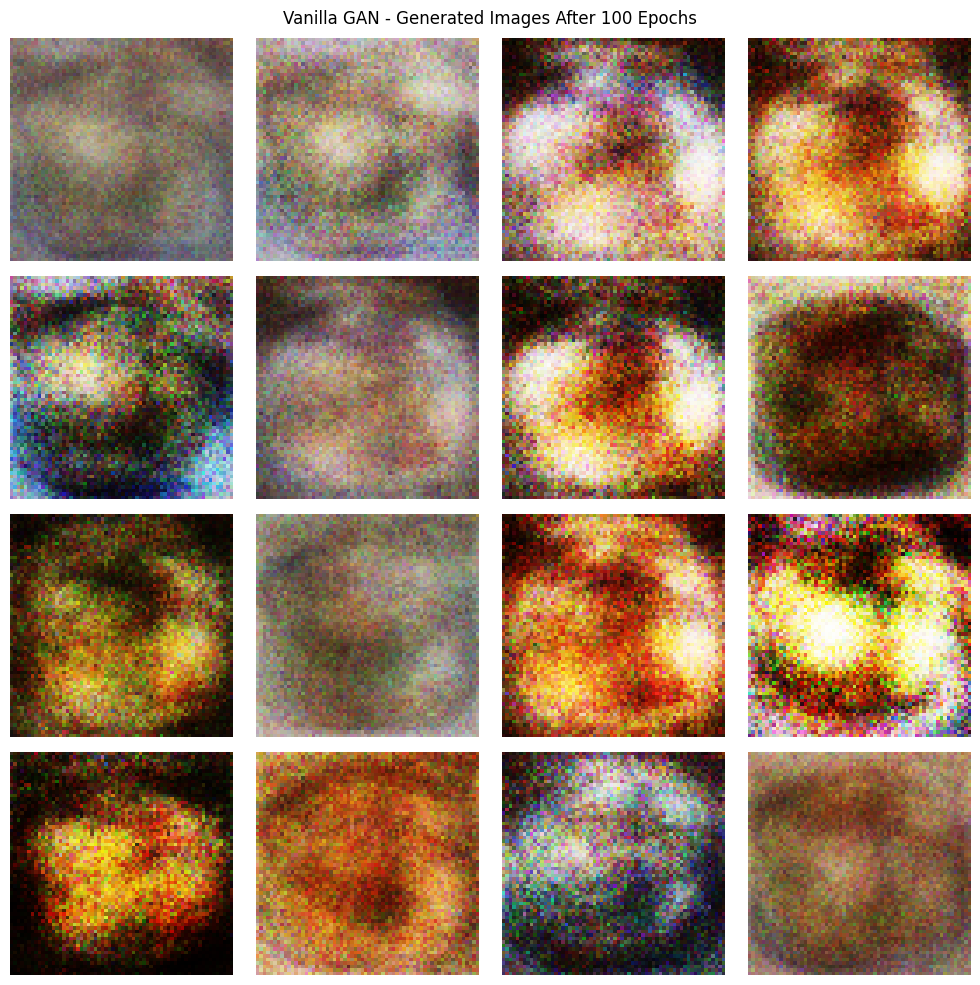

In [30]:
noise = tf.random.normal([16, LATENT_DIM])

vanilla_final_images = generator(noise, training=False)

# Convert [-1, 1] → [0, 1]
vanilla_final_images = (vanilla_final_images + 1) / 2.0

plt.figure(figsize=(10, 10))

for i in range(16):
    plt.subplot(4, 4, i + 1)
    plt.imshow(vanilla_final_images[i])
    plt.axis("off")

plt.suptitle("Vanilla GAN - Generated Images After 100 Epochs")
plt.tight_layout()
plt.show()

In [31]:
for epoch in range(100, 200):

    epoch_d_loss = []
    epoch_g_loss = []

    for real_images in dataset:
        d_loss, g_loss = train_step(real_images)

        epoch_d_loss.append(float(d_loss))
        epoch_g_loss.append(float(g_loss))

    avg_d_loss = sum(epoch_d_loss) / len(epoch_d_loss)
    avg_g_loss = sum(epoch_g_loss) / len(epoch_g_loss)

    vanilla_d_losses.append(avg_d_loss)
    vanilla_g_losses.append(avg_g_loss)

    print(
        f"Epoch {epoch + 1}/200 "
        f"- D Loss: {avg_d_loss:.4f} "
        f"- G Loss: {avg_g_loss:.4f}"
    )

Epoch 101/200 - D Loss: 0.4791 - G Loss: 2.2573
Epoch 102/200 - D Loss: 0.5107 - G Loss: 2.0610
Epoch 103/200 - D Loss: 0.4858 - G Loss: 2.0646
Epoch 104/200 - D Loss: 0.4802 - G Loss: 2.0163
Epoch 105/200 - D Loss: 0.5157 - G Loss: 2.0216
Epoch 106/200 - D Loss: 0.5270 - G Loss: 1.9901
Epoch 107/200 - D Loss: 0.5481 - G Loss: 1.9685
Epoch 108/200 - D Loss: 0.5267 - G Loss: 1.9969
Epoch 109/200 - D Loss: 0.5576 - G Loss: 1.8056
Epoch 110/200 - D Loss: 0.5768 - G Loss: 1.7908
Epoch 111/200 - D Loss: 0.5514 - G Loss: 1.7058
Epoch 112/200 - D Loss: 0.5621 - G Loss: 1.8051
Epoch 113/200 - D Loss: 0.5629 - G Loss: 1.7528
Epoch 114/200 - D Loss: 0.5468 - G Loss: 1.7339
Epoch 115/200 - D Loss: 0.5568 - G Loss: 1.7177
Epoch 116/200 - D Loss: 0.5612 - G Loss: 1.7142
Epoch 117/200 - D Loss: 0.5780 - G Loss: 1.7366
Epoch 118/200 - D Loss: 0.5834 - G Loss: 1.6256
Epoch 119/200 - D Loss: 0.5659 - G Loss: 1.6454
Epoch 120/200 - D Loss: 0.5674 - G Loss: 1.6482
Epoch 121/200 - D Loss: 0.5680 - G Loss:

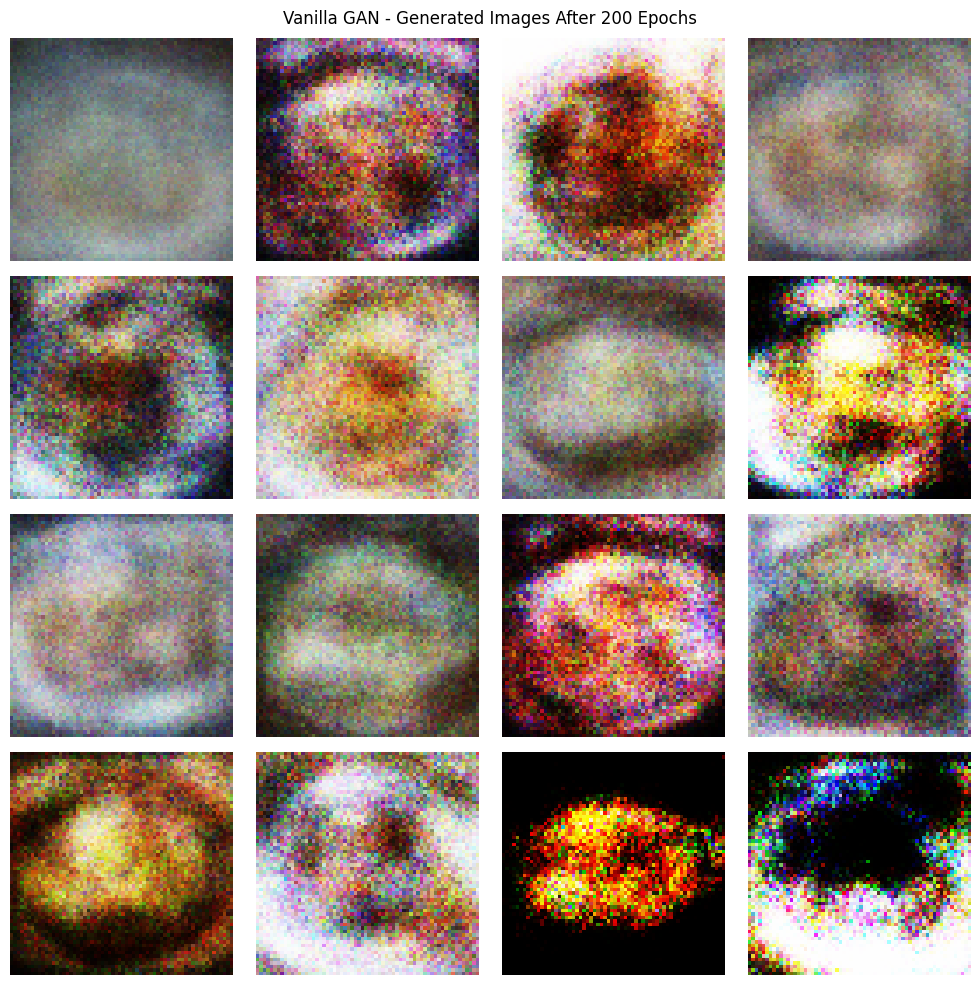

In [32]:
noise = tf.random.normal([16, LATENT_DIM])

vanilla_final_images_200 = generator(noise, training=False)

# Convert [-1, 1] → [0, 1]
vanilla_final_images_200 = (vanilla_final_images_200 + 1) / 2.0

plt.figure(figsize=(10, 10))

for i in range(16):
    plt.subplot(4, 4, i + 1)
    plt.imshow(vanilla_final_images_200[i])
    plt.axis("off")

plt.suptitle("Vanilla GAN - Generated Images After 200 Epochs")
plt.tight_layout()
plt.show()

In [33]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Reshape, BatchNormalization
from tensorflow.keras.layers import Conv2DTranspose, ReLU

dc_generator = Sequential([

    # Noise vector → 8×8×256
    Dense(8 * 8 * 256, input_shape=(LATENT_DIM,)),
    BatchNormalization(),
    ReLU(),

    Reshape((8, 8, 256)),

    # 8×8 → 16×16
    Conv2DTranspose(
        128,
        kernel_size=4,
        strides=2,
        padding="same"
    ),
    BatchNormalization(),
    ReLU(),

    # 16×16 → 32×32
    Conv2DTranspose(
        64,
        kernel_size=4,
        strides=2,
        padding="same"
    ),
    BatchNormalization(),
    ReLU(),

    # 32×32 → 64×64
    Conv2DTranspose(
        32,
        kernel_size=4,
        strides=2,
        padding="same"
    ),
    BatchNormalization(),
    ReLU(),

    # 64×64 RGB output
    Conv2DTranspose(
        3,
        kernel_size=4,
        strides=1,
        padding="same",
        activation="tanh"
    )

], name="DCGAN_Generator")

dc_generator.summary()

Model: "DCGAN_Generator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_8 (Dense)                 │ (None, 16384)          │     1,654,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 16384)          │        65,536 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 16384)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape_1 (Reshape)             │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 16, 16, 128)    │       524,416 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 32, 32, 64)     │       131,136 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_2              │ (None, 64, 64, 32)     │        32,800 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_3 (ReLU)                  │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_3              │ (None, 64, 64, 3)      │         1,539 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,411,107 (9.20 MB)

 Trainable params: 2,377,891 (9.07 MB)

 Non-trainable params: 33,216 (129.75 KB)

In [34]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Conv2D, LeakyReLU, Dropout
from tensorflow.keras.layers import Flatten, Dense

dc_discriminator = Sequential([

    # 64×64 → 32×32
    Conv2D(
        64,
        kernel_size=4,
        strides=2,
        padding="same",
        input_shape=(64, 64, 3)
    ),
    LeakyReLU(0.2),
    Dropout(0.3),

    # 32×32 → 16×16
    Conv2D(
        128,
        kernel_size=4,
        strides=2,
        padding="same"
    ),
    LeakyReLU(0.2),
    Dropout(0.3),

    # 16×16 → 8×8
    Conv2D(
        256,
        kernel_size=4,
        strides=2,
        padding="same"
    ),
    LeakyReLU(0.2),
    Dropout(0.3),

    # Classification
    Flatten(),
    Dense(1, activation="sigmoid")

], name="DCGAN_Discriminator")

dc_discriminator.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "DCGAN_Discriminator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 64)     │         3,136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 128)    │       131,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 8, 8, 256)      │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 16384)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 1)              │        16,385 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 675,265 (2.58 MB)

 Trainable params: 675,265 (2.58 MB)

 Non-trainable params: 0 (0.00 B)

In [35]:
d_optimizer = tf.keras.optimizers.Adam(
    learning_rate=0.0002,
    beta_1=0.5
)

g_optimizer = tf.keras.optimizers.Adam(
    learning_rate=0.0002,
    beta_1=0.5
)

bce = tf.keras.losses.BinaryCrossentropy()


@tf.function
def dcgan_train_step(real_images):

    batch_size = tf.shape(real_images)[0]

    # -------------------------
    # Train Discriminator
    # -------------------------
    noise = tf.random.normal([batch_size, LATENT_DIM])

    with tf.GradientTape() as d_tape:

        fake_images = dc_generator(noise, training=True)

        real_output = dc_discriminator(
            real_images,
            training=True
        )

        fake_output = dc_discriminator(
            fake_images,
            training=True
        )

        d_loss_real = bce(
            tf.ones_like(real_output),
            real_output
        )

        d_loss_fake = bce(
            tf.zeros_like(fake_output),
            fake_output
        )

        d_loss = (d_loss_real + d_loss_fake) / 2

    d_gradients = d_tape.gradient(
        d_loss,
        dc_discriminator.trainable_variables
    )

    d_optimizer.apply_gradients(
        zip(
            d_gradients,
            dc_discriminator.trainable_variables
        )
    )


    # -------------------------
    # Train Generator
    # -------------------------
    noise = tf.random.normal([batch_size, LATENT_DIM])

    with tf.GradientTape() as g_tape:

        fake_images = dc_generator(
            noise,
            training=True
        )

        fake_output = dc_discriminator(
            fake_images,
            training=False
        )

        g_loss = bce(
            tf.ones_like(fake_output),
            fake_output
        )

    g_gradients = g_tape.gradient(
        g_loss,
        dc_generator.trainable_variables
    )

    g_optimizer.apply_gradients(
        zip(
            g_gradients,
            dc_generator.trainable_variables
        )
    )

    return d_loss, g_loss

In [36]:
DCGAN_EPOCHS = 20

dcgan_d_losses = []
dcgan_g_losses = []

for epoch in range(DCGAN_EPOCHS):

    epoch_d_loss = []
    epoch_g_loss = []

    for real_images in dataset:

        d_loss, g_loss = dcgan_train_step(real_images)

        epoch_d_loss.append(float(d_loss))
        epoch_g_loss.append(float(g_loss))

    avg_d_loss = sum(epoch_d_loss) / len(epoch_d_loss)
    avg_g_loss = sum(epoch_g_loss) / len(epoch_g_loss)

    dcgan_d_losses.append(avg_d_loss)
    dcgan_g_losses.append(avg_g_loss)

    print(
        f"Epoch {epoch + 1}/{DCGAN_EPOCHS} "
        f"- D Loss: {avg_d_loss:.4f} "
        f"- G Loss: {avg_g_loss:.4f}"
    )

Epoch 1/20 - D Loss: 0.2122 - G Loss: 3.0798
Epoch 2/20 - D Loss: 0.5060 - G Loss: 4.2152
Epoch 3/20 - D Loss: 0.5513 - G Loss: 1.3865
Epoch 4/20 - D Loss: 0.5582 - G Loss: 1.3237
Epoch 5/20 - D Loss: 0.5642 - G Loss: 1.3647
Epoch 6/20 - D Loss: 0.6430 - G Loss: 1.1325
Epoch 7/20 - D Loss: 0.6653 - G Loss: 0.9748
Epoch 8/20 - D Loss: 0.6349 - G Loss: 0.9532
Epoch 9/20 - D Loss: 0.6455 - G Loss: 1.0561
Epoch 10/20 - D Loss: 0.6592 - G Loss: 1.0273
Epoch 11/20 - D Loss: 0.6298 - G Loss: 0.9438
Epoch 12/20 - D Loss: 0.6618 - G Loss: 1.0698
Epoch 13/20 - D Loss: 0.6222 - G Loss: 1.0018
Epoch 14/20 - D Loss: 0.6483 - G Loss: 1.0885
Epoch 15/20 - D Loss: 0.6470 - G Loss: 1.1209
Epoch 16/20 - D Loss: 0.6208 - G Loss: 1.0241
Epoch 17/20 - D Loss: 0.6542 - G Loss: 1.1488
Epoch 18/20 - D Loss: 0.6314 - G Loss: 0.9643
Epoch 19/20 - D Loss: 0.5816 - G Loss: 1.1466
Epoch 20/20 - D Loss: 0.6027 - G Loss: 1.2346


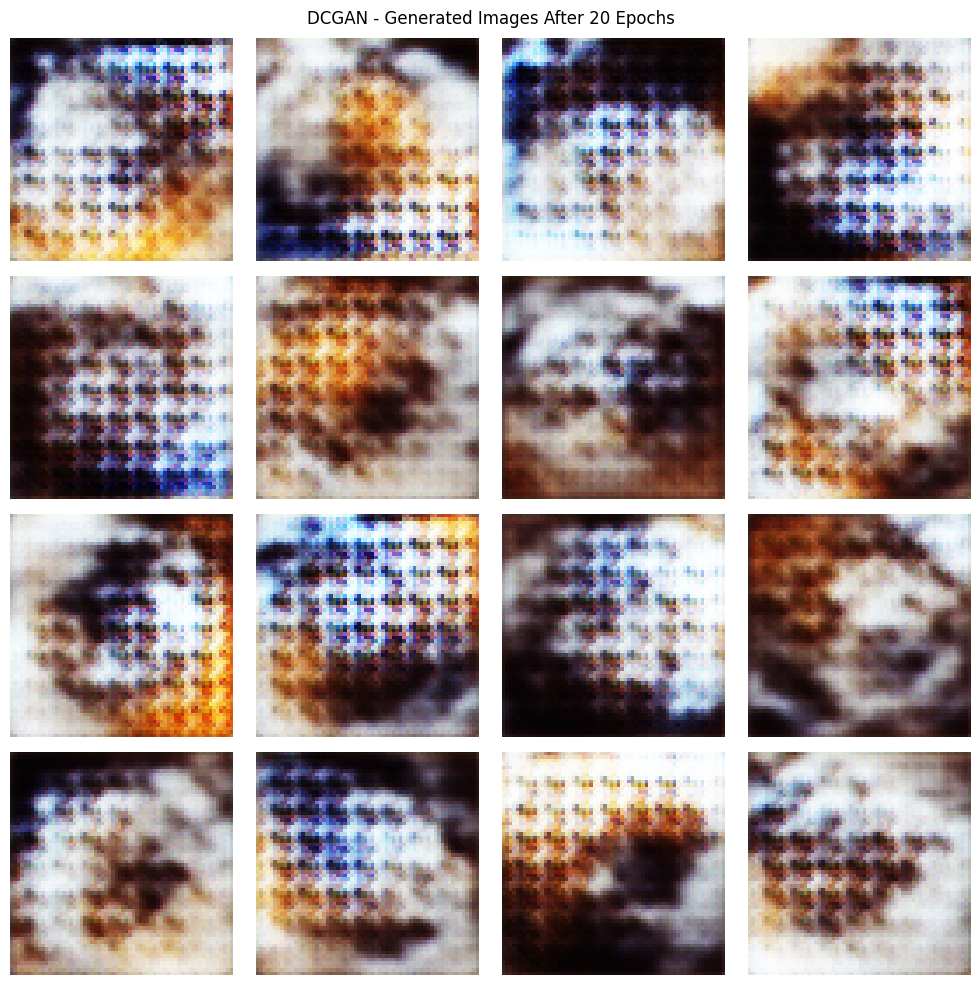

In [37]:
noise = tf.random.normal([16, LATENT_DIM])

dcgan_images_20 = dc_generator(noise, training=False)

# Convert [-1, 1] → [0, 1]
dcgan_images_20 = (dcgan_images_20 + 1) / 2.0

plt.figure(figsize=(10, 10))

for i in range(16):
    plt.subplot(4, 4, i + 1)
    plt.imshow(dcgan_images_20[i])
    plt.axis("off")

plt.suptitle("DCGAN - Generated Images After 20 Epochs")
plt.tight_layout()
plt.show()

In [38]:
for epoch in range(20, 100):

    epoch_d_loss = []
    epoch_g_loss = []

    for real_images in dataset:

        d_loss, g_loss = dcgan_train_step(real_images)

        epoch_d_loss.append(float(d_loss))
        epoch_g_loss.append(float(g_loss))

    avg_d_loss = sum(epoch_d_loss) / len(epoch_d_loss)
    avg_g_loss = sum(epoch_g_loss) / len(epoch_g_loss)

    dcgan_d_losses.append(avg_d_loss)
    dcgan_g_losses.append(avg_g_loss)

    print(
        f"Epoch {epoch + 1}/100 "
        f"- D Loss: {avg_d_loss:.4f} "
        f"- G Loss: {avg_g_loss:.4f}"
    )

Epoch 21/100 - D Loss: 0.6597 - G Loss: 1.1242
Epoch 22/100 - D Loss: 0.6531 - G Loss: 1.1079
Epoch 23/100 - D Loss: 0.6334 - G Loss: 1.0690
Epoch 24/100 - D Loss: 0.6381 - G Loss: 1.3098
Epoch 25/100 - D Loss: 0.6125 - G Loss: 1.1946
Epoch 26/100 - D Loss: 0.6209 - G Loss: 1.3705
Epoch 27/100 - D Loss: 0.6118 - G Loss: 1.3958
Epoch 28/100 - D Loss: 0.6444 - G Loss: 1.3665
Epoch 29/100 - D Loss: 0.6275 - G Loss: 1.1944
Epoch 30/100 - D Loss: 0.6164 - G Loss: 1.4589
Epoch 31/100 - D Loss: 0.6428 - G Loss: 1.1060
Epoch 32/100 - D Loss: 0.6262 - G Loss: 1.1241
Epoch 33/100 - D Loss: 0.6218 - G Loss: 1.2073
Epoch 34/100 - D Loss: 0.6471 - G Loss: 1.2821
Epoch 35/100 - D Loss: 0.6240 - G Loss: 1.1336
Epoch 36/100 - D Loss: 0.6167 - G Loss: 1.2248
Epoch 37/100 - D Loss: 0.6300 - G Loss: 1.3780
Epoch 38/100 - D Loss: 0.6341 - G Loss: 1.2084
Epoch 39/100 - D Loss: 0.6330 - G Loss: 1.3176
Epoch 40/100 - D Loss: 0.6275 - G Loss: 1.3148
Epoch 41/100 - D Loss: 0.6196 - G Loss: 1.1901
Epoch 42/100 

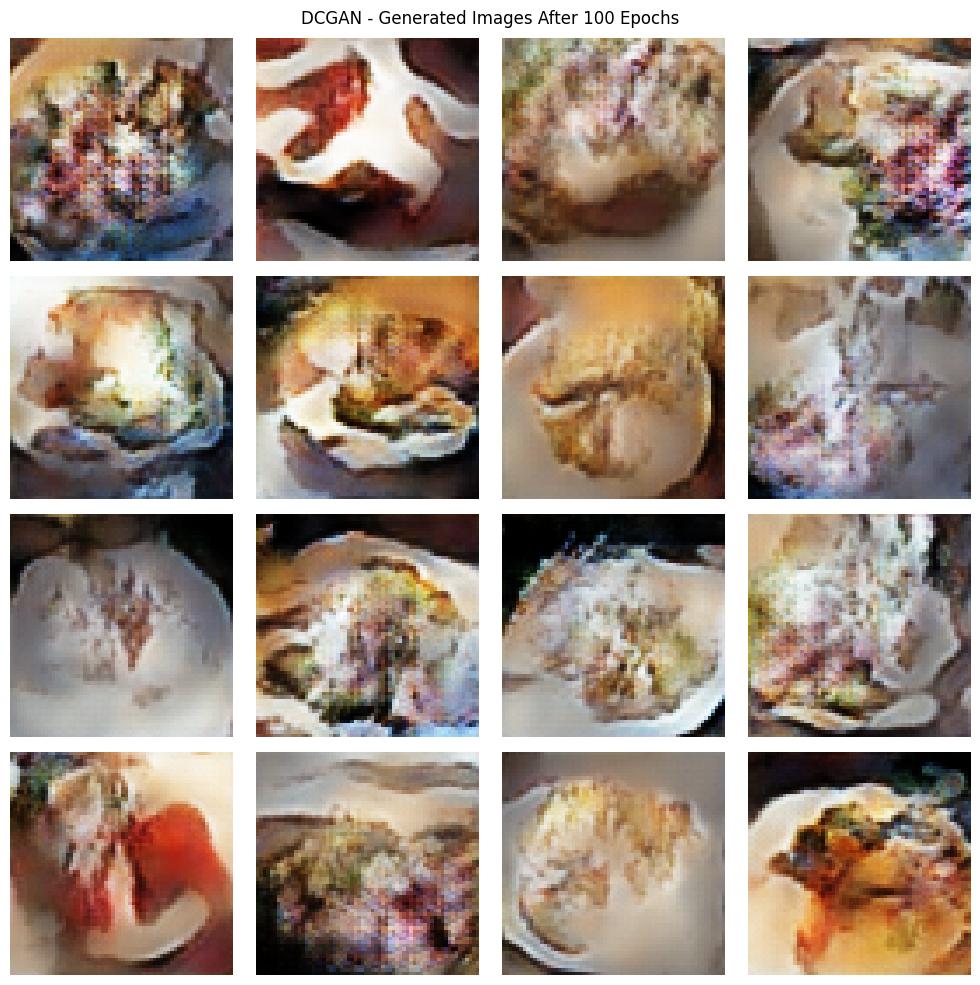

In [39]:
noise = tf.random.normal([16, LATENT_DIM])

dcgan_final_images = dc_generator(noise, training=False)

# Convert [-1, 1] → [0, 1]
dcgan_final_images = (dcgan_final_images + 1) / 2.0

plt.figure(figsize=(10, 10))

for i in range(16):
    plt.subplot(4, 4, i + 1)
    plt.imshow(dcgan_final_images[i])
    plt.axis("off")

plt.suptitle("DCGAN - Generated Images After 100 Epochs")
plt.tight_layout()
plt.show()

In [40]:
for epoch in range(100, 200):

    epoch_d_loss = []
    epoch_g_loss = []

    for real_images in dataset:

        d_loss, g_loss = dcgan_train_step(real_images)

        epoch_d_loss.append(float(d_loss))
        epoch_g_loss.append(float(g_loss))

    avg_d_loss = sum(epoch_d_loss) / len(epoch_d_loss)
    avg_g_loss = sum(epoch_g_loss) / len(epoch_g_loss)

    dcgan_d_losses.append(avg_d_loss)
    dcgan_g_losses.append(avg_g_loss)

    print(
        f"Epoch {epoch + 1}/200 "
        f"- D Loss: {avg_d_loss:.4f} "
        f"- G Loss: {avg_g_loss:.4f}"
    )

Epoch 101/200 - D Loss: 0.6081 - G Loss: 1.2278
Epoch 102/200 - D Loss: 0.6095 - G Loss: 1.2001
Epoch 103/200 - D Loss: 0.6103 - G Loss: 1.2101
Epoch 104/200 - D Loss: 0.6014 - G Loss: 1.2243
Epoch 105/200 - D Loss: 0.6066 - G Loss: 1.2366
Epoch 106/200 - D Loss: 0.6155 - G Loss: 1.1995
Epoch 107/200 - D Loss: 0.6051 - G Loss: 1.2347
Epoch 108/200 - D Loss: 0.6129 - G Loss: 1.2360
Epoch 109/200 - D Loss: 0.6107 - G Loss: 1.1894
Epoch 110/200 - D Loss: 0.6109 - G Loss: 1.1762
Epoch 111/200 - D Loss: 0.6079 - G Loss: 1.1995
Epoch 112/200 - D Loss: 0.6136 - G Loss: 1.1738
Epoch 113/200 - D Loss: 0.6108 - G Loss: 1.1901
Epoch 114/200 - D Loss: 0.6058 - G Loss: 1.2033
Epoch 115/200 - D Loss: 0.6118 - G Loss: 1.1957
Epoch 116/200 - D Loss: 0.6147 - G Loss: 1.2099
Epoch 117/200 - D Loss: 0.6095 - G Loss: 1.1588
Epoch 118/200 - D Loss: 0.6123 - G Loss: 1.1903
Epoch 119/200 - D Loss: 0.6149 - G Loss: 1.2216
Epoch 120/200 - D Loss: 0.6111 - G Loss: 1.1795
Epoch 121/200 - D Loss: 0.6058 - G Loss:

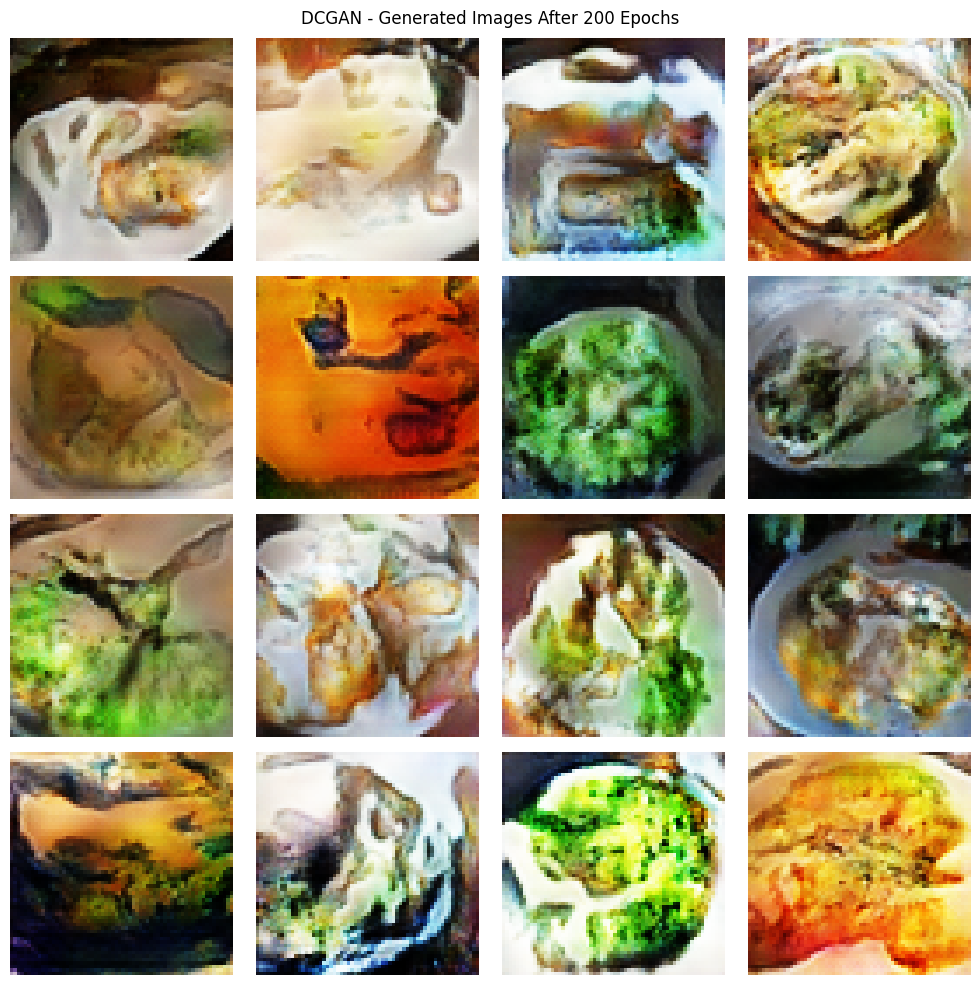

In [41]:
noise = tf.random.normal([16, LATENT_DIM])

dcgan_final_images_200 = dc_generator(
    noise,
    training=False
)

# Convert [-1, 1] → [0, 1]
dcgan_final_images_200 = (dcgan_final_images_200 + 1) / 2.0

plt.figure(figsize=(10, 10))

for i in range(16):
    plt.subplot(4, 4, i + 1)
    plt.imshow(dcgan_final_images_200[i])
    plt.axis("off")

plt.suptitle("DCGAN - Generated Images After 200 Epochs")
plt.tight_layout()
plt.show()